In [ ]:
"""
Figure S2 - Ice velocity at KAN_U between 01-06-2023 and 01-10-2023.
Author: Hannah Picton 
Date: 27th March 2026
Description: This notebook plots a timeseries of ice velocity (15-day average) at KAN_U between 01-06-2023 and 01-10-2023. The required ice velocity 
file 'kanu_2021_121_2024_121_disp_velocity_15d_epochs.csv' can be downloaded at Tedstone et al. (2026; https://doi.org/10.5281/zenodo.18611668).
"""

# Import libraries 
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

# -- PROVIDE PATH TO ICE VELOCITY DATA --
vel_15day_file_path = '.../data/kanu_2021_121_2024_121_disp_velocity_15d_epochs.csv' # UPDATE FILEPATH

# Data preparation - 15-day velocity data
# ==========================================================================================
date_column_name = 'Date'
value_column = 'v_myr'
uncertainty_column = 'v_uncertainty_myr'
start_date = '2023-06-01'
end_date = '2023-10-01'

# Define colours for plotting
velocity_colour = '#14213d'
uncertainty_colour = "#0F879C"

# Load the velocity data, convert the date column to datetime format, and set it as the index
df_vel = pd.read_csv(vel_15day_file_path, sep=',', header=0)
df_vel[date_column_name] = pd.to_datetime(df_vel[date_column_name], format='%d/%m/%Y', dayfirst=True)
df_vel.set_index(date_column_name, inplace=True)
df_vel[uncertainty_column] = pd.to_numeric(df_vel[uncertainty_column], errors='coerce').fillna(0) 

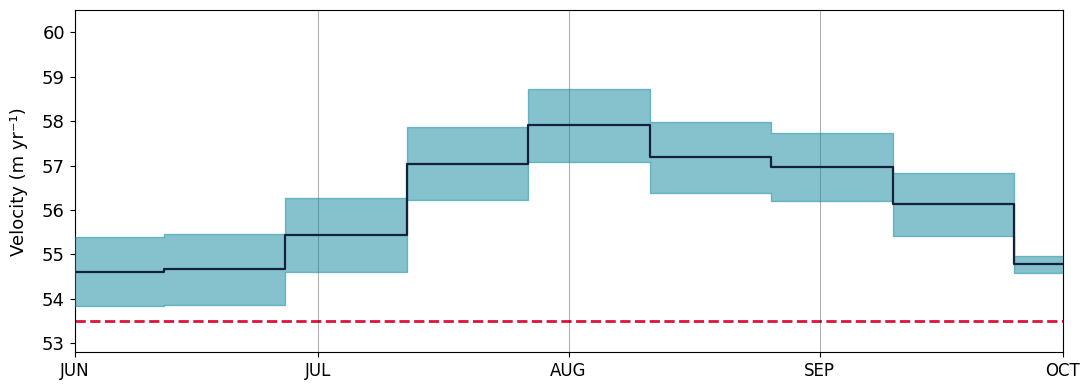

In [2]:
# Plot ice velocity at KAN_U between 01-06-2023 and 01-10-2023.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df_vel.index, df_vel[value_column], color=velocity_colour, drawstyle='steps-post', linewidth=1.6, zorder=5)
ax.axhline(y=53.5, color='crimson', linestyle='--', linewidth=2, zorder=0, label='Mean Winter Velocity\n(64.7 m yr⁻¹)')
# Uncertainty 
y_lower = df_vel[value_column] - df_vel[uncertainty_column]
y_upper = df_vel[value_column] + df_vel[uncertainty_column]
ax.fill_between(df_vel.index, y_lower, y_upper, color=uncertainty_colour, step='post', alpha=0.5, zorder=3)
# Plot formatting
ax.set_ylim(52.8, 60.5)
ax.set_ylabel('Velocity (m yr⁻¹)', fontsize=13, labelpad=10)
ax.tick_params(axis='y', labelsize=13)
ax.set_xlim(pd.to_datetime(start_date), pd.to_datetime(end_date))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: mdates.num2date(x).strftime('%b').upper()))
ax.tick_params(axis='x', which='major', labelsize=12)
ax.grid(axis='x', linestyle='-', color='black', alpha=0.3)
fig.tight_layout()
plt.show()